# Exercice 40 — Composition d'ε-AEFND

## 1. Union de deux automates

On ajoute un nouvel état initial $s$, relié par des transitions $\varepsilon$ aux états initiaux des deux automates.

Les états finaux sont ceux de $A_1$ et $A_2$.

L'automate obtenu reconnaît $L_1 \cup L_2$.

### Construction mathématique

Soient deux ε-AEFND :

- $A_1=(Q_1,\Sigma,\Delta_1,q_1^0,F_1)$
- $A_2=(Q_2,\Sigma,\Delta_2,q_2^0,F_2)$

On suppose que leurs ensembles d'états sont disjoints et que $s$ est un nouvel état.

On construit l'automate :

$$
A_{\cup}=(Q_{\cup},\Sigma,\Delta_{\cup},q_{\cup}^0,F_{\cup})
$$

avec :

$$
Q_{\cup}=Q_1\cup Q_2\cup\{s\}
$$

$$
q_{\cup}^0=s
$$

$$
F_{\cup}=F_1\cup F_2
$$

On conserve toutes les transitions des deux automates et on ajoute :

$$
\Delta_{\cup}(s,\varepsilon)=\{q_1^0,q_2^0\}
$$

Ainsi, l'automate peut choisir d'exécuter $A_1$ ou $A_2$ sans consommer de symbole.

### Conclusion

Dans notre exemple :

$$
L_1=a^*,\qquad L_2=b^*
$$

L'automate accepte les mots composés uniquement de `a`, uniquement de `b`, ainsi que le mot vide.

On obtient donc :

$$
\boxed{L(A_{\cup})=L_1\cup L_2=a^*\cup b^*}
$$

### Vérification avec Automatix

On considère deux AEFND :

- $A_1$ reconnaît $L_1 = a^*$.
- $A_2$ reconnaît $L_2 = b^*$.

On construit leur union et on vérifie les mots reconnus.

In [10]:
from automata_extensions.fa.nfa import ExtendedNFA

A1 = ExtendedNFA(
    states={"p0", "p1"},
    input_symbols={"a", "b"},
    transitions={
        "p0": {
            "a": {"p0", "p1"},
            "": {"p1"},
        },
        "p1": {
            "a": {"p1"},
        },
    },
    initial_state="p0",
    final_states={"p1"},
)


In [11]:
A2 = ExtendedNFA(
    states={"q0", "q1"},
    input_symbols={"a", "b"},
    transitions={
        "q0": {
            "b": {"q0", "q1"},
            "": {"q1"},
        },
        "q1": {
            "b": {"q1"},
        },
    },
    initial_state="q0",
    final_states={"q1"},
)



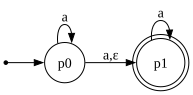

In [13]:
A1.show_diagram()

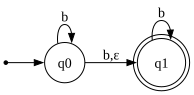

In [14]:
A2.show_diagram()

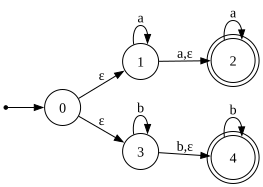

In [15]:
A_union = A1.union(A2)

A_union.show_diagram()

In [16]:
mots = ["", "a", "aa", "b", "bb", "ab", "ba", "aab"]

for mot in mots:
    print(f"{mot or 'ε':>3} -> {A_union.accepts_input(mot)}")

  ε -> True
  a -> True
 aa -> True
  b -> True
 bb -> True
 ab -> False
 ba -> False
aab -> False


L'automate obtenu accepte les mots composés uniquement de `a`,
uniquement de `b`, ainsi que le mot vide.

On vérifie donc :

$$
\boxed{L(A_{\cup}) = L_1 \cup L_2 = a^* \cup b^*}
$$

## 2. Concaténation

On relie chaque état final de $A_1$ à l'état initial de $A_2$ par une transition $\varepsilon$.

L'état initial est celui de $A_1$, et les états finaux sont ceux de $A_2$.

L'automate obtenu reconnaît $L_1 \cdot L_2$.

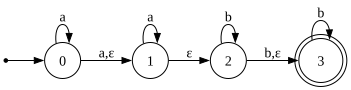

In [17]:
A_concat = A1.concatenation(A2)

A_concat.show_diagram()

In [18]:
mots = ["", "a", "b", "ab", "aab", "abb", "aaabbb", "ba", "aba"]

for mot in mots:
    print(f"{mot or 'ε':>6} -> {A_concat.accepts_input(mot)}")

     ε -> True
     a -> True
     b -> True
    ab -> True
   aab -> True
   abb -> True
aaabbb -> True
    ba -> False
   aba -> False


La concaténation reconnaît les mots composés d'une suite de `a` suivie d'une suite de `b`, éventuellement vides.

$$
\boxed{L(A_{\cdot})=a^*b^*}
$$

## 3. Étoile de Kleene

On ajoute un nouvel état initial et final $s$, relié par une transition $\varepsilon$ à l'ancien état initial.

Depuis chaque ancien état final, une transition $\varepsilon$ permet de recommencer l'exécution.

L'automate obtenu reconnaît $L_1^*$.

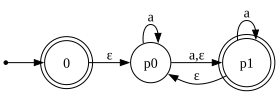

In [19]:
A_star = A1.kleene_star()

A_star.show_diagram()

In [20]:
mots = ["", "a", "aa", "aaa", "b", "ab", "ba"]

for mot in mots:
    print(f"{mot or 'ε':>3} -> {A_star.accepts_input(mot)}")

  ε -> True
  a -> True
 aa -> True
aaa -> True
  b -> False
 ab -> False
 ba -> False


Comme $L_1 = a^*$, appliquer à nouveau l'étoile de Kleene ne change pas le langage :

$$
\boxed{L(A_*) = L_1^* = (a^*)^* = a^*}
$$

## 4. Intersection

On construit l'automate produit, dont les états sont des couples $(p,q)$ avec $p \in Q_1$ et $q \in Q_2$.

Un état est final si ses deux composantes sont finales.

L'automate obtenu reconnaît les mots acceptés par les deux automates.

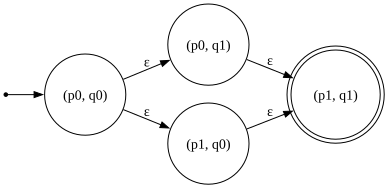

In [22]:
A_inter = A1.intersection(A2)
A_inter.show_diagram()

In [23]:


mots = ["", "a", "aa", "b", "bb", "ab", "ba"]

for mot in mots:
    resultat = A_inter.accepts_input(mot)
    print(f"{mot or 'ε':>3} -> {resultat}")

  ε -> True
  a -> False
 aa -> False
  b -> False
 bb -> False
 ab -> False
 ba -> False


### Construction mathématique et conclusion

Soient deux ε-AEFND :

- $A_1=(Q_1,\Sigma,\Delta_1,q_1^0,F_1)$
- $A_2=(Q_2,\Sigma,\Delta_2,q_2^0,F_2)$

On construit l'automate produit :

$$
A_{\cap}=(Q_{\cap},\Sigma,\Delta_{\cap},q_{\cap}^0,F_{\cap})
$$

avec :

$$
Q_{\cap}=Q_1\times Q_2
$$

$$
q_{\cap}^0=(q_1^0,q_2^0)
$$

$$
F_{\cap}=F_1\times F_2
$$

Pour tout symbole $x\in\Sigma$, la fonction de transition est :

$$
\Delta_{\cap}((p,q),x)
=\Delta_1(p,x)\times\Delta_2(q,x)
$$

Pour les transitions $\varepsilon$, chaque automate peut avancer indépendamment :

$$
\Delta_{\cap}((p,q),\varepsilon)
=
(\Delta_1(p,\varepsilon)\times\{q\})
\cup
(\{p\}\times\Delta_2(q,\varepsilon))
$$

### Conclusion

L'automate produit accepte un mot si et seulement si les deux automates l'acceptent.

Dans notre exemple :

$$
L_1=a^*,\qquad L_2=b^*
$$

Le seul mot appartenant aux deux langages est le mot vide $\varepsilon$.

On obtient donc :

$$
\boxed{L(A_{\cap})=L_1\cap L_2=\{\varepsilon\}}
$$